In [ ]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"

from pathlib import Path

import qim3d
from cil.io import TIFFWriter
from cil.processors import TransmissionAbsorptionConverter
from cil.recon import FDK
from cil.utilities.display import show2D, show_geometry
from gvxrPython3.cil.JSON2gVXRDataReader import JSON2gVXRDataReader

import common

In [ ]:
data_dir = common.data_dir
print(f"{data_dir=}")

case_dir=PosixPath('/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/integrated_case')
data_dir=PosixPath('/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/integrated_case/data')


In [60]:
data = JSON2gVXRDataReader(str(data_dir / "projections" / "simulation.json")).read()

[512, 512]
[0.020000000298023225, 0.020000000298023225]


In [61]:
# Because we get full attentuation for some parts of the object,
# we need to handle the case of zero photon count

arr = data.as_array()
min_val = arr[arr > 0].min()
data = TransmissionAbsorptionConverter(min_intensity=min_val)(data)

In [62]:
ig = data.geometry.get_ImageGeometry()
recon = FDK(data, ig).run()


FDK recon

Input Data:
	angle: 805
	vertical: 512
	horizontal: 512

Reconstruction Volume:
	vertical: 512
	horizontal_y: 512
	horizontal_x: 512

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 10
	Filter_inplace: False



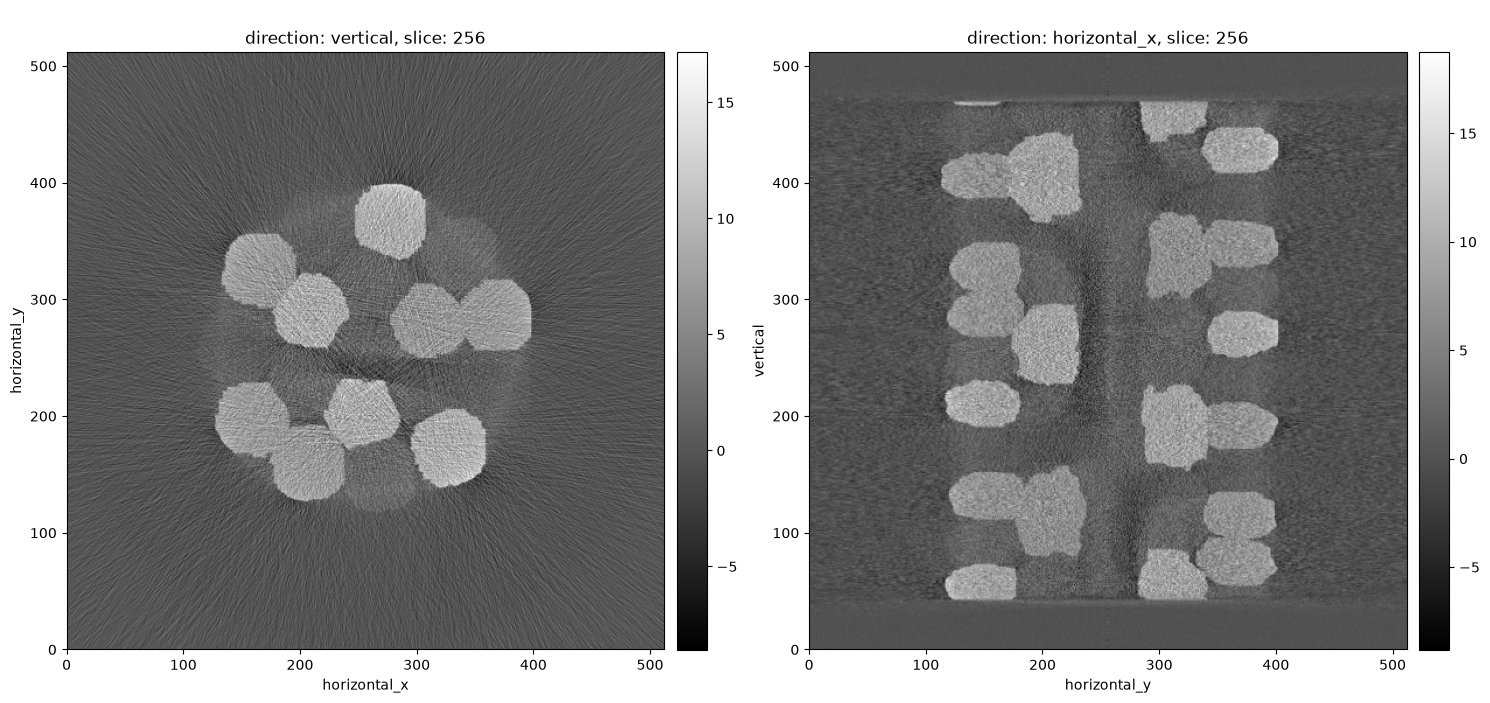

In [63]:
show2D(
    recon,
    slice_list=[("vertical", 256), ("horizontal_x", 256)],
)

In [64]:
qim3d.viz.planes(recon.as_array(), colormap="plasma")

FigureWidget({
    'data': [{'cmax': 255,
              'cmin': 0,
              'colorscale': [[0.0, 'rgb(13, 8, 135)'], [0.00392156862745098,
                             'rgb(16, 7, 136)'], [0.00784313725490196, 'rgb(19, 7,
                             137)'], ..., [0.9921568627450981, 'rgb(241, 245,
                             37)'], [0.996078431372549, 'rgb(240, 247, 36)'], [1.0,
                             'rgb(240, 249, 33)']],
              'lighting': {'ambient': 1, 'diffuse': 0, 'fresnel': 0, 'roughness': 1, 'specular': 0},
              'name': 'Z',
              'opacity': 1.0,
              'showlegend': False,
              'showscale': False,
              'surfacecolor': array([[ 78,  94,  95, ...,  69,  91,  98],
                                     [ 82,  86,  91, ...,  88, 102,  88],
                                     [ 83,  81,  83, ..., 103,  87,  88],
                                     ...,
                                     [101,  87,  85, ...,  87,  83, 

In [ ]:
writer = TIFFWriter(
    recon,
    file_name=data_dir / "reconstruction_fdk" / "slice",
)
writer.write()
